**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**25 | Final Model Selection and Development Protocol Freeze**

![Stage 25 scientific workflow](../../images/25_workflow.svg)

**Objective:** Review recorded Development evidence from Notebooks 23–24 to recommend a primary model, reference classifier and reproducible final evaluation protocol.

**Dataset:** Saved HARTH v2.0 Development results from 29 participants and the fixed 14,201-window bounded task; no Test recordings are opened.

**Notebook Scope:** Compare seven model configurations and 36 robustness fits, document the proposed 1D-ResNet and Random Forest settings and verify the existing protocol records without rewriting them. **Historical and subsequent approval status:** The original and reconciled Stage 25 proposal records retain `PENDING_USER_REVIEW` to preserve their proposal-time state. This is not the final Test authorisation status: the separate immutable `stage_25_protocol_approved_qualified_test.json` records `APPROVED` for the subsequently completed, one-time qualified Stage 26 Test evaluation. Replaying Notebook 25 only verifies this existing approval lineage; it does not grant new Test authorisation or fit a model.

**Evaluation boundary:** S023 and S032 were inspected descriptively earlier in the study, so any later held-out evaluation must disclose that prior exposure. Selection is based on saved Development evidence and is not an independent estimate of final performance.

**00. Colab Repository Setup — external preparation (not an executable study cell)**

This notebook is part of the approved research evidence chain. Start a temporary setup notebook in the **same Colab runtime** and run the following; avoid adding an extra executable code cell to the saved Stage 25 evidence.

```python
from pathlib import Path
repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content
if not repo_path.exists():
    !git clone -q {repo_url}
%cd {repo_path}
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")
from core.plot_style import plot_style
plot_style()
```

**Evidence:** The frozen selection manifest, saved execution counts and documented approval status are unchanged.

**01. Imports and Saved Evidence Utilities**

In [2]:
# ================= 01. Imports and Saved Evidence Utilities ==================

# ----------------------------- Standard Library ------------------------------
from pathlib import Path
import sys
import json
import hashlib

# ---------------------- Scientific Evidence and Tables -----------------------
import numpy as np
import pandas as pd

# -------------------- Visualisation and Notebook Display ---------------------
import matplotlib.pyplot as plt
from IPython.display import display

# ----------------------- Repository and Source Imports -----------------------
root=Path.cwd().resolve()
while not (root/"python_modules/core/harth_selection_evidence.py").is_file():
    if root.parent==root: raise RuntimeError("Run within the HMI repository.")
    root=root.parent
sys.path.insert(0,str(root/"python_modules"))

# --------------------- Saved Research Evidence Utilities ---------------------
from core.harth_selection_evidence import load_selection_evidence

# --------------------- Development Evidence Verification ---------------------
notebooks=root/"wearable_activity_recognition/code/notebooks"
evidence=load_selection_evidence(
    notebooks/"23_unified_matched_model_benchmark.ipynb",
    notebooks/"24_multiseed_and_imbalance_robustness.ipynb",
)
print(""+"="*66)
print("STAGE 25 | DEVELOPMENT-ONLY MODEL SELECTION")
print("="*66)
print("Source SHA256:",evidence["development_sha256"])
print("Stage 23 notebook SHA256:",evidence["notebook23_sha256"])
print("Stage 24 notebook SHA256:",evidence["notebook24_sha256"])
print("Original Test data loaded: NO")
print("="*66)


STAGE 25 | DEVELOPMENT-ONLY MODEL SELECTION
Source SHA256: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Stage 23 notebook SHA256: 3623e4317bff0b15bc58b9642923bee6d7b277bc509a3f6973b325466c1c92ec
Stage 24 notebook SHA256: 0cb911b6c3fdc400ea185e9fc4184fac351c408f931beacaba9010a31ab73c6d
Original Test data loaded: NO


**02. Review Seven-Model Development Results**

Use the saved benchmark outputs without training new models. Differences in input representation and loss weighting mean a model ranking cannot isolate architectural effects. The multi-seed evidence is available for ResNet and TCN, not equivalently for Random Forest or every other neural configuration.

,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,accuracy_mean,total_train_seconds,total_inference_seconds,parameters
0,1D-ResNet,0.8328,0.0435,0.8688,0.9468,33.0217,0.1304,91176
1,TCN,0.8138,0.0658,0.8575,0.9365,9.3827,0.1335,38056
2,Random Forest,0.8094,0.0500,0.8063,0.9532,13.3388,0.1800,0
3,Time-Series Transformer,0.8006,0.0602,0.8552,0.9338,13.2878,0.3920,38744
4,Multi-Scale CNN,0.7946,0.0459,0.8392,0.9364,8.7932,0.1501,16488
5,Weighted CNN,0.7725,0.0274,0.8022,0.9412,4.2729,0.0480,12392
6,Standard CNN,0.6664,0.0633,0.6575,0.9378,7.5230,0.1166,12392


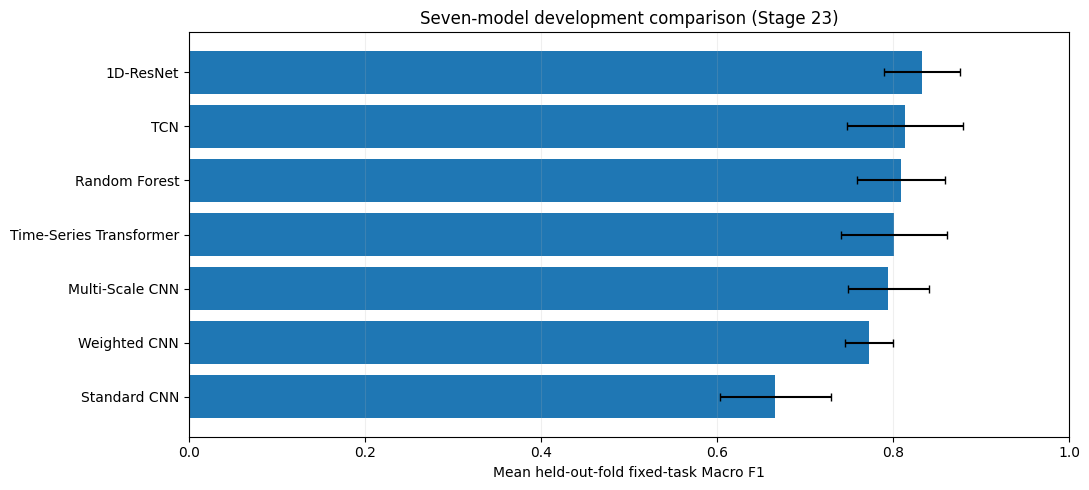

In [3]:
# ================ 02. Review Seven-Model Development Results =================

# ------------- Present all seven saved Development model scores --------------
benchmark=evidence["stage23"].sort_values("macro_f1_mean",ascending=False)
display(benchmark.round(4))

# --------------- Plot saved Macro F1 means and fold variation ----------------
fig,ax=plt.subplots(figsize=(11,5))
ax.barh(benchmark["model"],benchmark["macro_f1_mean"],
        xerr=benchmark["macro_f1_sd"],capsize=3)
ax.invert_yaxis()
ax.set(xlim=(0,1),xlabel="Mean held-out-fold fixed-task Macro F1",
       title="Seven-model development comparison (Stage 23)")
ax.grid(axis="x",alpha=.2)
fig.tight_layout()
plt.show()


**03. Inspect Stability Across Seeds and Folds**

Compare the predefined seeds `42`, `123` and `2026` across the same three Development GroupKFold splits and 400-update neural budget. Report mean and standard deviation descriptively. Repeated seeds on the same participants do not create independent evaluation cohorts.

In [4]:
# =============== 03. Inspect Stability Across Seeds and Folds ================

# ------------ Display the four predeclared model-loss conditions -------------
seed_summary=evidence["stage24_summary"].sort_values(
    "mean_across_seed_fold_macro_f1",ascending=False
)
display(seed_summary.round(4))

# ------------ Compare weighted ResNet and TCN under matched folds ------------
weighted=evidence["stage24_folds"].query("loss_method == 'weighted_ce'")
paired=weighted.pivot(index=["seed","fold"],columns="architecture",values="macro_f1")
paired["ResNet_minus_TCN"]=paired["1D-ResNet"]-paired["TCN"]
display(paired.round(4))
print("Mean matched-fold difference:",
      round(paired["ResNet_minus_TCN"].mean(),4))
print("This comparison is exploratory and development-only.")


,architecture,loss_method,mean_across_seed_fold_macro_f1,across_seed_sd,total_training_s
0,1D-ResNet,weighted_ce,0.8286,0.0052,99.7251
1,TCN,weighted_ce,0.8105,0.0079,27.7609
2,1D-ResNet,focal,0.8058,0.0053,99.9784
3,1D-ResNet,class_balanced,0.7915,0.0191,99.5433


architecture  1D-ResNet     TCN  ResNet_minus_TCN
seed fold                                        
42   1           0.7879  0.7634            0.0245
     2           0.8360  0.7898            0.0462
     3           0.8747  0.8883           -0.0136
123  1           0.7966  0.7876            0.0090
     2           0.8219  0.7554            0.0665
     3           0.8723  0.8616            0.0107
2026 1           0.8260  0.8167            0.0093
     2           0.7799  0.7487            0.0312
     3           0.8625  0.8831           -0.0206

Mean matched-fold difference: 0.0181
This comparison is exploratory and development-only.


**04. Evaluate Loss Choices and Minority-Class Trade-offs**

Weighted Cross-Entropy led the ResNet loss formulations in mean Development Macro F1 in Notebook 24. Focal and Class-Balanced Cross-Entropy are not uniformly better for minority activities. Random Forest retains stronger Shuffling F1 in the original matched benchmark, supporting its role as a fixed reference.

In [5]:
# ========== 04. Evaluate Loss Choices and Minority-Class Trade-offs ==========

# -------------- Compare ResNet loss results across paired folds --------------
resnet=evidence["stage24_folds"].query("architecture == '1D-ResNet'")
loss_table=resnet.pivot(index=["seed","fold"],columns="loss_method",values="macro_f1")
display(loss_table.round(4))
loss_means=resnet.groupby("loss_method",as_index=False)["macro_f1"].mean()
display(loss_means.sort_values("macro_f1",ascending=False).round(4))

# ---------------- Report Shuffling and stair-class trade-offs ----------------
class_report=evidence["stage23_classes"].copy()
class_report=class_report[
    class_report["model"].isin(["Random Forest","1D-ResNet","TCN"])
    & class_report["class_code"].isin([3,4,5])
]
display(class_report[[
    "model","class_code","support","precision","recall","f1"
]].round(4))
assert len(class_report)==9


loss_method  class_balanced   focal  weighted_ce
seed fold                                       
42   1               0.7471  0.7687       0.7879
     2               0.7699  0.7807       0.8360
     3               0.8725  0.8681       0.8747
123  1               0.7823  0.7385       0.7966
     2               0.8030  0.8229       0.8219
     3               0.8376  0.8720       0.8723
2026 1               0.7624  0.8043       0.8260
     2               0.6843  0.7833       0.7799
     3               0.8644  0.8139       0.8625

,loss_method,macro_f1
2,weighted_ce,0.8286
1,focal,0.8058
0,class_balanced,0.7915


,model,class_code,support,precision,recall,f1
2,Random Forest,3,219,0.4756,0.5342,0.5032
3,Random Forest,4,192,0.7310,0.5521,0.6291
4,Random Forest,5,182,0.7031,0.4945,0.5806
26,TCN,3,219,0.2959,0.3973,0.3392
27,TCN,4,192,0.5385,0.8750,0.6667
28,TCN,5,182,0.5468,0.8022,0.6503
42,1D-ResNet,3,219,0.3422,0.4703,0.3962
43,1D-ResNet,4,192,0.5375,0.8594,0.6613
44,1D-ResNet,5,182,0.6946,0.7747,0.7325


**05. Recommend Primary and Reference Models**

The proposed primary model is 1D-ResNet with inverse-square-root weighted Cross-Entropy. Seed `42` is a reproducibility convention rather than a choice based on maximum observed performance. A 120-tree Random Forest is retained as a fixed classical reference; TCN remains part of the Development evidence without adding an unplanned candidate to later Test scoring.

The recommendation reflects mean fixed-task Macro F1, stability and known minority-class limitations; it is not a statistically confirmed claim of model-family superiority.

In [6]:
# ================ 05. Recommend Primary and Reference Models =================

# ---------- Check the selected method against Development evidence -----------
candidate=seed_summary.iloc[0]
assert candidate["architecture"]=="1D-ResNet"
assert candidate["loss_method"]=="weighted_ce"

# --------------- Document the selected model and alternatives ----------------
decision=pd.DataFrame([
    {"role":"Primary for proposed Stage 26","architecture":"1D-ResNet",
     "training":"Inverse-square-root Weighted CE","reason":"Highest mean Macro F1 across three seeds and three folds"},
    {"role":"Fixed classical reference","architecture":"Random Forest",
     "training":"Balanced-subsample RF","reason":"Higher observed Shuffling F1 in matched Stage 23"},
    {"role":"Development-only neural comparator","architecture":"TCN",
     "training":"Inverse-square-root Weighted CE","reason":"Strong development results; lower mean across seeds"},
    {"role":"Not selected","architecture":"ResNet Focal / Class-Balanced",
     "training":"Alternative loss ablations","reason":"Lower Stage 24 average fixed-eight-class Macro F1"},
])
display(decision)
print("Primary model candidate: 1D-ResNet + Weighted CE")
print("Proposed final seed: 42 (fixed convention, not best-seed tuning)")
print("No Test-based decision performed.")


,role,architecture,training,reason
0,Primary for proposed Stage 26,1D-ResNet,Inverse-square-root Weighted CE,Highest mean Macro F1 across three seeds and t...
1,Fixed classical reference,Random Forest,Balanced-subsample RF,Higher observed Shuffling F1 in matched Stage 23
2,Development-only neural comparator,TCN,Inverse-square-root Weighted CE,Strong development results; lower mean across ...
3,Not selected,ResNet Focal / Class-Balanced,Alternative loss ablations,Lower Stage 24 average fixed-eight-class Macro F1


Primary model candidate: 1D-ResNet + Weighted CE
Proposed final seed: 42 (fixed convention, not best-seed tuning)
No Test-based decision performed.


**06. Specify Source, Labels and Participant Roles**

Propose the pinned HARTH v2.0 source revision, six acceleration channels, nominal 50 Hz sampling, 100-sample windows, 50-sample stride, strict label purity, timestamp-continuity checks and activity codes 1–8. Exclude out-of-task codes after windowing and reserve S023/S032 for one separately qualified evaluation.

Use the same label-independent, 500-window-per-participant cap for all 29 Development participants rather than silently switching to the full 132,397-window cohort.

In [7]:
# ============= 06. Specify Source, Labels and Participant Roles ==============

# ----------- Specify source provenance, cohort and window protocol -----------
source_protocol=pd.DataFrame([
    {"property":"Source revision","frozen_value":"dad2cfbe89a26f72f19770419469ac037de200df"},
    {"property":"Nominal sampling rate","frozen_value":"50 Hz"},
    {"property":"Window length","frozen_value":"100 samples (2 seconds)"},
    {"property":"Stride","frozen_value":"50 samples"},
    {"property":"Purity / continuity","frozen_value":"100% one documented source label; strict timestamp checks"},
    {"property":"Target class codes","frozen_value":"1, 2, 3, 4, 5, 6, 7, 8"},
    {"property":"Development","frozen_value":"29 people; chronological cap 500; 14,201 windows"},
    {"property":"Original reserved Test","frozen_value":"S023 and S032; no access in Stage 25"},
    {"property":"Original source axes","frozen_value":"Back and thigh accelerometer (three axes each)"},
])
display(source_protocol)
assert len(evidence["development_sha256"])==64


,property,frozen_value
0,Source revision,dad2cfbe89a26f72f19770419469ac037de200df
1,Nominal sampling rate,50 Hz
2,Window length,100 samples (2 seconds)
3,Stride,50 samples
4,Purity / continuity,100% one documented source label; strict times...
5,Target class codes,"1, 2, 3, 4, 5, 6, 7, 8"
6,Development,"29 people; chronological cap 500; 14,201 windows"
7,Original reserved Test,S023 and S032; no access in Stage 25
8,Original source axes,Back and thigh accelerometer (three axes each)


**07. Propose Final Training Settings**

The primary ResNet configuration uses 400 Adam updates, batch size 128, learning rate `0.001` and seed `42`. Fit channel scaling and class weights on Development only and save them with the trained model. The reference Random Forest uses 30 statistical features, 120 trees, minimum leaf size three, balanced-subsample weights and seed `42`.

No calibration procedure is included because Notebook 19 did not show consistent improvement in NLL.

In [8]:
# ==================== 07. Propose Final Training Settings ====================

# --------------- Record all proposed final-training parameters ---------------
training_config=pd.DataFrame([
    {"setting":"Primary architecture","value":"1D-ResNet, hidden_channels=32"},
    {"setting":"Loss","value":"Fold/Development-only inverse-square-root Weighted CE"},
    {"setting":"Optimiser","value":"Adam, learning_rate=0.001"},
    {"setting":"Budget","value":"400 optimiser updates, batch size=128"},
    {"setting":"Seed","value":"42"},
    {"setting":"CNN preprocessing","value":"Development-only per-axis mean/SD; preserve channel order"},
    {"setting":"RF reference","value":"120 trees, min_samples_leaf=3, balanced_subsample"},
    {"setting":"Final checkpoint","value":"Last update only, no Test-driven selection"},
    {"setting":"Temperature scaling","value":"Not included"},
])
display(training_config)


,setting,value
0,Primary architecture,"1D-ResNet, hidden_channels=32"
1,Loss,Fold/Development-only inverse-square-root Weig...
2,Optimiser,"Adam, learning_rate=0.001"
3,Budget,"400 optimiser updates, batch size=128"
4,Seed,42
5,CNN preprocessing,Development-only per-axis mean/SD; preserve ch...
6,RF reference,"120 trees, min_samples_leaf=3, balanced_subsample"
7,Final checkpoint,"Last update only, no Test-driven selection"
8,Temperature scaling,Not included


**08. Predefine the Qualified Held-Out Evaluation**

Use fixed eight-class Macro F1 as the primary reported metric, with accuracy, balanced accuracy, confusion matrices, class-level precision/recall/F1, true support, participant-level scores and computational cost. The separately approved protocol prohibits using Test results to revise the architecture, seed, sampling, loss or number of training updates.

Because the reserved participants had earlier descriptive exposure and come from the same study, this is a qualified retrospective held-out evaluation, not a strictly blind external benchmark.

In [9]:
# ============== 08. Predefine the Qualified Held-Out Evaluation ==============

# ------------- Document frozen evaluation rules and restrictions -------------
rules=pd.DataFrame([
    {"item":"Primary evaluation","fixed_rule":"Eight-class Macro F1 with original source class order"},
    {"item":"Secondary outcomes","fixed_rule":"Balanced accuracy, accuracy, class precision/recall/F1 and support"},
    {"item":"Participant reporting","fixed_rule":"Scores for both original reserved participants separately"},
    {"item":"Model comparisons","fixed_rule":"One primary ResNet and one fixed RF reference; no Test-guided choice"},
    {"item":"Preprocessing","fixed_rule":"Fit only on 29-person Development"},
    {"item":"Selection and stopping","fixed_rule":"400 final updates; no Test-based checkpoint selection"},
    {"item":"Unmapped labels","fixed_rule":"Preserve original codes; exclude post-windowing"},
    {"item":"Evidence limitation","fixed_rule":"Previously inspected reserved people, not strictly blind external Test"},
])
display(rules)


,item,fixed_rule
0,Primary evaluation,Eight-class Macro F1 with original source clas...
1,Secondary outcomes,"Balanced accuracy, accuracy, class precision/r..."
2,Participant reporting,Scores for both original reserved participants...
3,Model comparisons,One primary ResNet and one fixed RF reference;...
4,Preprocessing,Fit only on 29-person Development
5,Selection and stopping,400 final updates; no Test-based checkpoint se...
6,Unmapped labels,Preserve original codes; exclude post-windowing
7,Evidence limitation,"Previously inspected reserved people, not stri..."


**09. Verify the Frozen Stage 25 Protocol and Source Fingerprints**

Reconstruct the Development-only model proposal from the saved Stage 23/24 evidence, then verify the exact six frozen source modules against the previously reconciled SHA256 digests. The original and reconciled proposals are immutable `PENDING_USER_REVIEW` records from the proposal phase. The separate, immutable approved manifest records the actual subsequent qualified-Test authorisation used in Stage 26. The displayed pending proposal status must not be re-labelled as an approval. This is a read-only replay: verify the frozen scientific settings and existing approval lineage without overwriting records, creating a new approval, refitting models or opening Test recordings. On Windows, only an exact CRLF-to-LF representation of otherwise unchanged source code is accepted.

In [10]:
# ====== 09. Verify the Frozen Stage 25 Protocol and Source Fingerprints ======

# -------- Hash the exact source modules that implement this pipeline ---------
paths=[
    "code/python/src/core/advanced_temporal_models.py",
    "code/python/src/core/temporal_cnn.py",
    "code/python/src/core/temporal_benchmark.py",
    "code/python/src/core/feature_engineering.py",
    "code/python/src/core/robustness_experiments.py",
    "studies/wearable_activity_recognition/src/harth_data.py",
]
from core.harth_protocol_lineage import (
    verified_module_sha256, verify_preexisting_stage25_lineage,
    resolve_frozen_source_path,
)
evidence_dir=root/"wearable_activity_recognition/evidence"
reconciled=json.loads(
    (evidence_dir/"stage_25_protocol_proposal_reconciled.json").read_text(
        encoding="utf-8"
    )
)
expected_sha=reconciled["module_sha256"]
assert set(paths)==set(expected_sha), "Unexpected frozen source-module list."
code_sha={}
for name in paths:
    file=resolve_frozen_source_path(root,name)
    assert file.is_file(),name
    code_sha[name]=verified_module_sha256(file,expected_sha[name])

# --------------- Create a Development-based selection proposal ---------------
manifest={
    "schema":"harth-final-protocol-v1",
    "status":"PENDING_USER_REVIEW",
    "source_development_sha256":evidence["development_sha256"],
    "stage23_saved_notebook_sha256":evidence["notebook23_sha256"],
    "stage24_saved_notebook_sha256":evidence["notebook24_sha256"],
    "primary_model":{
        "architecture":"1D-ResNet","hidden_channels":32,"in_channels":6,
        "classes":list(range(1,9)),"training_loss":"inverse_sqrt_weighted_ce",
        "random_seed":42,"optimizer":"Adam","learning_rate":0.001,
        "batch_size":128,"optimizer_steps":400,"checkpoint":"final_step",
        "preprocessing":"Development-only per-channel mean and SD",
    },
    "reference_model":{
        "architecture":"Random Forest","n_estimators":120,
        "min_samples_leaf":3,"class_weight":"balanced_subsample",
        "seed":42,"features":["mean","std","rms","peak_to_peak","waveform_length"],
    },
    "source":{
        "dataset":"HARTH v2.0",
        "revision":"dad2cfbe89a26f72f19770419469ac037de200df",
        "sampling_rate_hz":50,"window_size":100,"step_size":50,
        "annotation_purity":1.0,"timestamp_continuity":True,
        "task_codes":list(range(1,9)),
        "development_participants":29,"cap_per_development_person":500,
        "expected_development_windows":14201,
        "reserved_test_people":["S023","S032"],
        "test_cap_per_person":500,
        "unknown_source_codes":"Preserve and exclude after time-safe windowing",
    },
    "evaluation":{
        "main_metric":"Fixed-eight-class Macro F1",
        "additional":["accuracy","balanced_accuracy",
                      "per-class precision/recall/F1/support",
                      "per-person fixed-task Macro F1","confusion matrices"],
        "use_test_for_tuning":False,
        "temperature_scaling":False,
        "description":"Qualified previously-inspected reserved Test, not fully blind external validation",
    },
    "module_sha256":code_sha,
}

# ----------- Verify previously reviewed manifests; never overwrite -----------
lineage=verify_preexisting_stage25_lineage(manifest,evidence_dir)
print("Historical original proposal:",lineage["original_proposal"])
print("Reconciled pending protocol:",lineage["reconciled_proposal"])
print("Previous qualified-Test approval:",lineage["existing_approval"])
print("New authorisation granted by replay:",lineage["new_approval_granted"])
print("Protocol files written:",lineage["files_written"])
print("Code module SHA256 entries:",len(code_sha))
print("Test recordings read during Stage 25: NO")


Historical original proposal: PRESERVED
Reconciled pending protocol: MATCHED
Previous qualified-Test approval: VERIFIED_EXISTING_ONLY
New authorisation granted by replay: False
Protocol files written: 0
Code module SHA256 entries: 6
Test recordings read during Stage 25: NO


**10. Summarise Selection Rationale and Historical Review**

Present the Development-based preference for weighted 1D-ResNet alongside Random Forest's Shuffling advantage and the remaining class-level limitations. The historical protocol review covered the primary model, reference classifier, 500-window cap, treatment of previously inspected S023/S032 and predefined evaluation metrics. Its original review requirements remain visible as provenance; the separately approved record and resulting qualified evaluation are preserved in Stage 26.

In [11]:
# ========== 10. Summarise Selection Rationale and Historical Review ==========

# ----------- Present the candidate and alternative-model rationale -----------
review=pd.DataFrame([
    {"item":"Primary final candidate","proposal":"1D-ResNet + Weighted CE","requires_approval":True},
    {"item":"Classic reference","proposal":"Random Forest 120-tree","requires_approval":True},
    {"item":"Bounded cohort","proposal":"500 source windows/person","requires_approval":True},
    {"item":"Held-out set","proposal":"S023, S032 (historically inspected)","requires_approval":True},
    {"item":"Single final seed","proposal":"42, fixed convention","requires_approval":True},
    {"item":"Allowed scoring","proposal":"One qualified held-out evaluation after approval","requires_approval":True},
])
display(review)
print("Development evidence supports this proposed configuration.")
print("Explicit user approval before Stage 26: REQUIRED")


,item,proposal,requires_approval
0,Primary final candidate,1D-ResNet + Weighted CE,True
1,Classic reference,Random Forest 120-tree,True
2,Bounded cohort,500 source windows/person,True
3,Held-out set,"S023, S032 (historically inspected)",True
4,Single final seed,"42, fixed convention",True
5,Allowed scoring,One qualified held-out evaluation after approval,True


Development evidence supports this proposed configuration.
Explicit user approval before Stage 26: REQUIRED


**11. Scientific Protocol Quality Gate**

Verify the referenced seven-model and 36-job Development evidence, explicit model settings, source fingerprints and absence of Test access in this decision stage. A passing gate checks proposal completeness and existing historical approval lineage; it does not fit a model, grant a new Test authorisation or establish independent generalisation.

In [12]:
# =================== 11. Scientific Protocol Quality Gate ====================

# ------------ Check saved evidence and model proposal consistency ------------
assert len(evidence["stage23"])==7
assert len(evidence["stage24_folds"])==36
assert len(evidence["stage24_summary"])==4
assert manifest["status"]=="PENDING_USER_REVIEW"
assert lineage["reconciled_proposal"]=="MATCHED"
assert lineage["existing_approval"]=="VERIFIED_EXISTING_ONLY"
assert lineage["files_written"]==0
assert not lineage["new_approval_granted"]
assert manifest["source_development_sha256"]==evidence["development_sha256"]
assert len(manifest["module_sha256"])==6

# ----------- Check primary settings and reserved participant roles -----------
assert manifest["primary_model"]["architecture"]=="1D-ResNet"
assert manifest["primary_model"]["random_seed"]==42
assert manifest["primary_model"]["optimizer_steps"]==400
assert manifest["source"]["reserved_test_people"]==["S023","S032"]
assert not manifest["evaluation"]["use_test_for_tuning"]
assert manifest["evaluation"]["main_metric"]=="Fixed-eight-class Macro F1"

# ---------- Provide a truthful, reader-friendly completion summary -----------
print(""+"="*70)
print("STAGE 25: FINAL MODEL SELECTION AND PROTOCOL PROPOSAL")
print("="*70)
print("Source-matched completed Development evidence: PASSED")
print("Seven-model Stage 23 evaluation reviewed: PASSED")
print("Three-seed/loss Stage 24 evidence reviewed: PASSED")
print("Primary development candidate: 1D-ResNet + Weighted CE")
print("Fixed reference model: Random Forest")
print("Protocol module/source digests: RECORDED")
print("Protected Test subjects loaded: NO")
print("-"*70)
print("Stage 25 development selection audit: PASSED")
print("Historical proposal status: PENDING USER REVIEW")
print("Previously approved qualified-Test lineage: VERIFIED")
print("New Test evaluation authorised: NO")
print("Test evaluation performed by this rerun: NO")
print("Next: review completion evidence before any further research stage")
print("="*70)


STAGE 25: FINAL MODEL SELECTION AND PROTOCOL PROPOSAL
Source-matched completed Development evidence: PASSED
Seven-model Stage 23 evaluation reviewed: PASSED
Three-seed/loss Stage 24 evidence reviewed: PASSED
Primary development candidate: 1D-ResNet + Weighted CE
Fixed reference model: Random Forest
Protocol module/source digests: RECORDED
Protected Test subjects loaded: NO
----------------------------------------------------------------------
Stage 25 development selection audit: PASSED
Historical proposal status: PENDING USER REVIEW
Previously approved qualified-Test lineage: VERIFIED
New Test evaluation authorised: NO
Test evaluation performed by this rerun: NO
Next: review completion evidence before any further research stage
